# Body-fat SHAP plots with regression p-values

This notebook produces the statistical reference requested for the expert survey. For each raw measurement displayed in the SHAP beeswarm plots, it fits a separate univariable ordinary least-squares regression:

$$\text{Body-fat percentage}=\beta_0+\beta_1(\text{measurement})+\epsilon.$$

The regressions use all 252 observations in the original body-fat dataset. The SHAP plots continue to use the 51 held-out test cases saved by the existing analysis. The regression p-values are **not SHAP p-values**: they test whether the marginal linear association between a measurement and observed body-fat percentage differs from zero. SHAP instead describes how a fitted model uses that measurement.

The notebook exports a complete regression table and survey-ready Random Forest and XGBoost beeswarm plots with the corresponding regression p-value beside each feature name.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Image, display
from scipy.stats import linregress, t


def find_project_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / 'data/bodyfat/bodyfat.csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Could not locate data/bodyfat/bodyfat.csv from the current directory.'
    )


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / 'data/bodyfat/bodyfat.csv'
PREPARED_DIR = PROJECT_ROOT / 'hpc_results/bodyfat/prepared'
ANALYSIS_DIR = PROJECT_ROOT / 'outputs/bodyfat/analysis'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/bodyfat/statistical_summary'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = 'BodyFat'
FEATURES = [
    'Age', 'Weight', 'Height', 'Neck', 'Chest', 'Abdomen', 'Hip',
    'Thigh', 'Knee', 'Ankle', 'Biceps', 'Forearm', 'Wrist',
]
UNITS = {
    'Age': 'years',
    'Weight': 'lb',
    'Height': 'in',
    **{feature: 'cm' for feature in FEATURES[3:]},
}

# Change these labels if the anonymous order in the form is different.
MODEL_PLOTS = {
    'random_forest': ('Model A', 'model_a_random_forest_shap_with_pvalues.png'),
    'xgboost': ('Model B', 'model_b_xgboost_shap_with_pvalues.png'),
}

print(f'Project root: {PROJECT_ROOT}')
print(f'Output:       {OUTPUT_DIR}')

Project root: c:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project
Output:       c:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\bodyfat\statistical_summary


## Load and validate the data and saved SHAP values

`Density` is excluded because body-fat percentage was calculated from it. The derived abdomen-to-chest and hip-to-thigh ratios were inputs to the fitted models, but the existing model-agnostic SHAP analysis explains the 13 raw measurements and recomputes the ratios internally. The regression rows therefore match those same 13 displayed measurements.

In [3]:
required_paths = [
    DATA_PATH,
    PREPARED_DIR / 'X_test.csv',
    ANALYSIS_DIR / 'shap_values.npz',
]
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f'Missing required project artefacts: {missing}')

bodyfat = pd.read_csv(DATA_PATH)
X_test = pd.read_csv(PREPARED_DIR / 'X_test.csv', index_col=0)
shap_archive = np.load(ANALYSIS_DIR / 'shap_values.npz')

required_columns = [TARGET, *FEATURES]
missing_columns = [column for column in required_columns if column not in bodyfat]
if missing_columns:
    raise ValueError(f'Original dataset is missing columns: {missing_columns}')
if list(X_test.columns[:len(FEATURES)]) != FEATURES:
    raise ValueError('The prepared test feature order does not match FEATURES.')
if bodyfat[required_columns].isna().any().any():
    raise ValueError('Regression variables contain missing values.')
if not np.isfinite(bodyfat[required_columns].to_numpy(dtype=float)).all():
    raise ValueError('Regression variables contain non-finite values.')

for key in MODEL_PLOTS:
    if key not in shap_archive.files:
        raise KeyError(f'{key!r} is not present in the saved SHAP archive.')
    expected_shape = (len(X_test), len(FEATURES))
    if shap_archive[key].shape != expected_shape:
        raise ValueError(
            f'{key} SHAP array has shape {shap_archive[key].shape}; '
            f'expected {expected_shape}.'
        )

print(f'Regression dataset: {len(bodyfat)} observations')
print(f'SHAP test set:      {len(X_test)} observations')
print(f'Regression features: {len(FEATURES)}')
display(bodyfat[required_columns].head())

Regression dataset: 252 observations
SHAP test set:      51 observations
Regression features: 13


,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


## Separate univariable regressions

The raw coefficient is expressed in body-fat percentage points per measurement unit. The standardised coefficient expresses the change in outcome standard deviations for a one-standard-deviation increase in the measurement, allowing effect magnitudes to be compared across different units. The table also includes Benjamini–Hochberg-adjusted p-values to document the effect of testing 13 features simultaneously; the survey plots show the conventional unadjusted regression p-values requested by the supervisor.

In [4]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted_ranked = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted_ranked = np.minimum.accumulate(adjusted_ranked[::-1])[::-1]
    adjusted = np.empty_like(adjusted_ranked)
    adjusted[order] = np.clip(adjusted_ranked, 0.0, 1.0)
    return adjusted


def univariable_regression(frame, feature, target):
    data = frame[[feature, target]].dropna()
    x = data[feature].to_numpy(dtype=float)
    y = data[target].to_numpy(dtype=float)
    n = len(data)
    critical_t = t.ppf(0.975, df=n - 2)

    raw = linregress(x, y)
    x_standardised = (x - x.mean()) / x.std(ddof=1)
    y_standardised = (y - y.mean()) / y.std(ddof=1)
    standardised = linregress(x_standardised, y_standardised)

    return {
        'Feature': feature,
        'Unit': UNITS[feature],
        'N': n,
        'Mean': x.mean(),
        'SD': x.std(ddof=1),
        'Median': np.median(x),
        'Q1': np.quantile(x, 0.25),
        'Q3': np.quantile(x, 0.75),
        'Raw coefficient': raw.slope,
        'Raw 95% CI lower': raw.slope - critical_t * raw.stderr,
        'Raw 95% CI upper': raw.slope + critical_t * raw.stderr,
        'Standardised beta': standardised.slope,
        'Standardised 95% CI lower': (
            standardised.slope - critical_t * standardised.stderr
        ),
        'Standardised 95% CI upper': (
            standardised.slope + critical_t * standardised.stderr
        ),
        'Pearson r': raw.rvalue,
        'R-squared': raw.rvalue ** 2,
        'p-value': raw.pvalue,
    }


regression_results = pd.DataFrame(
    [univariable_regression(bodyfat, feature, TARGET) for feature in FEATURES]
)
regression_results['BH-adjusted p-value'] = benjamini_hochberg(
    regression_results['p-value']
)
regression_results['Significant at p < .05'] = (
    regression_results['p-value'] < 0.05
)
regression_results['Significant after BH adjustment'] = (
    regression_results['BH-adjusted p-value'] < 0.05
)

display_columns = [
    'Feature', 'Unit', 'N', 'Mean', 'SD', 'Raw coefficient',
    'Raw 95% CI lower', 'Raw 95% CI upper', 'Standardised beta',
    'Standardised 95% CI lower', 'Standardised 95% CI upper',
    'p-value', 'BH-adjusted p-value',
]
display(
    regression_results[display_columns].style.format(
        {
            'Mean': '{:.2f}',
            'SD': '{:.2f}',
            'Raw coefficient': '{:.3f}',
            'Raw 95% CI lower': '{:.3f}',
            'Raw 95% CI upper': '{:.3f}',
            'Standardised beta': '{:.3f}',
            'Standardised 95% CI lower': '{:.3f}',
            'Standardised 95% CI upper': '{:.3f}',
            'p-value': '{:.3g}',
            'BH-adjusted p-value': '{:.3g}',
        }
    )
)

,Feature,Unit,N,Mean,SD,Raw coefficient,Raw 95% CI lower,Raw 95% CI upper,Standardised beta,Standardised 95% CI lower,Standardised 95% CI upper,p-value,BH-adjusted p-value
0,Age,years,252,44.88,12.60,0.194,0.114,0.273,0.291,0.172,0.411,2.52e-06,2.98e-06
1,Weight,lb,252,178.92,29.39,0.174,0.146,0.202,0.612,0.514,0.711,2.47e-27,8.04e-27
2,Height,in,252,70.15,3.66,-0.204,-0.488,0.079,-0.089,-0.214,0.035,0.157,0.157
3,Neck,cm,252,37.99,2.43,1.689,1.315,2.063,0.491,0.382,0.599,1.15e-16,1.86e-16
4,Chest,cm,252,100.82,8.43,0.697,0.609,0.785,0.703,0.614,0.791,8.09e-39,5.26e-38
5,Abdomen,cm,252,92.56,10.78,0.631,0.575,0.688,0.813,0.741,0.886,9.09e-61,1.18e-59
6,Hip,cm,252,99.90,7.16,0.730,0.617,0.844,0.625,0.528,0.722,9.82e-29,4.25e-28
7,Thigh,cm,252,59.41,5.25,0.892,0.727,1.057,0.560,0.456,0.663,3.61e-22,9.39e-22
8,Knee,cm,252,38.59,2.41,1.765,1.393,2.137,0.509,0.401,0.616,5.47e-18,1.18e-17
9,Ankle,cm,252,23.10,1.69,1.313,0.720,1.906,0.266,0.146,0.386,1.88e-05,2.04e-05


In [5]:
full_table_path = OUTPUT_DIR / 'univariable_regression_results.csv'
regression_results.to_csv(full_table_path, index=False)

form_table = regression_results[
    [
        'Feature', 'Unit', 'Standardised beta',
        'Standardised 95% CI lower', 'Standardised 95% CI upper',
        'p-value', 'BH-adjusted p-value',
    ]
].copy()
form_table_path = OUTPUT_DIR / 'survey_regression_reference.csv'
form_table.to_csv(form_table_path, index=False)

print(f'Saved: {full_table_path}')
print(f'Saved: {form_table_path}')

Saved: c:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\bodyfat\statistical_summary\univariable_regression_results.csv
Saved: c:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\bodyfat\statistical_summary\survey_regression_reference.csv


## Survey-ready beeswarm plots

The p-value appended to each feature label comes from its separate univariable regression above. It is identical in Models A and B because it describes the feature–outcome association in the dataset, not the feature's contribution to a particular model.

Saved: c:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\bodyfat\statistical_summary\model_a_random_forest_shap_with_pvalues.png


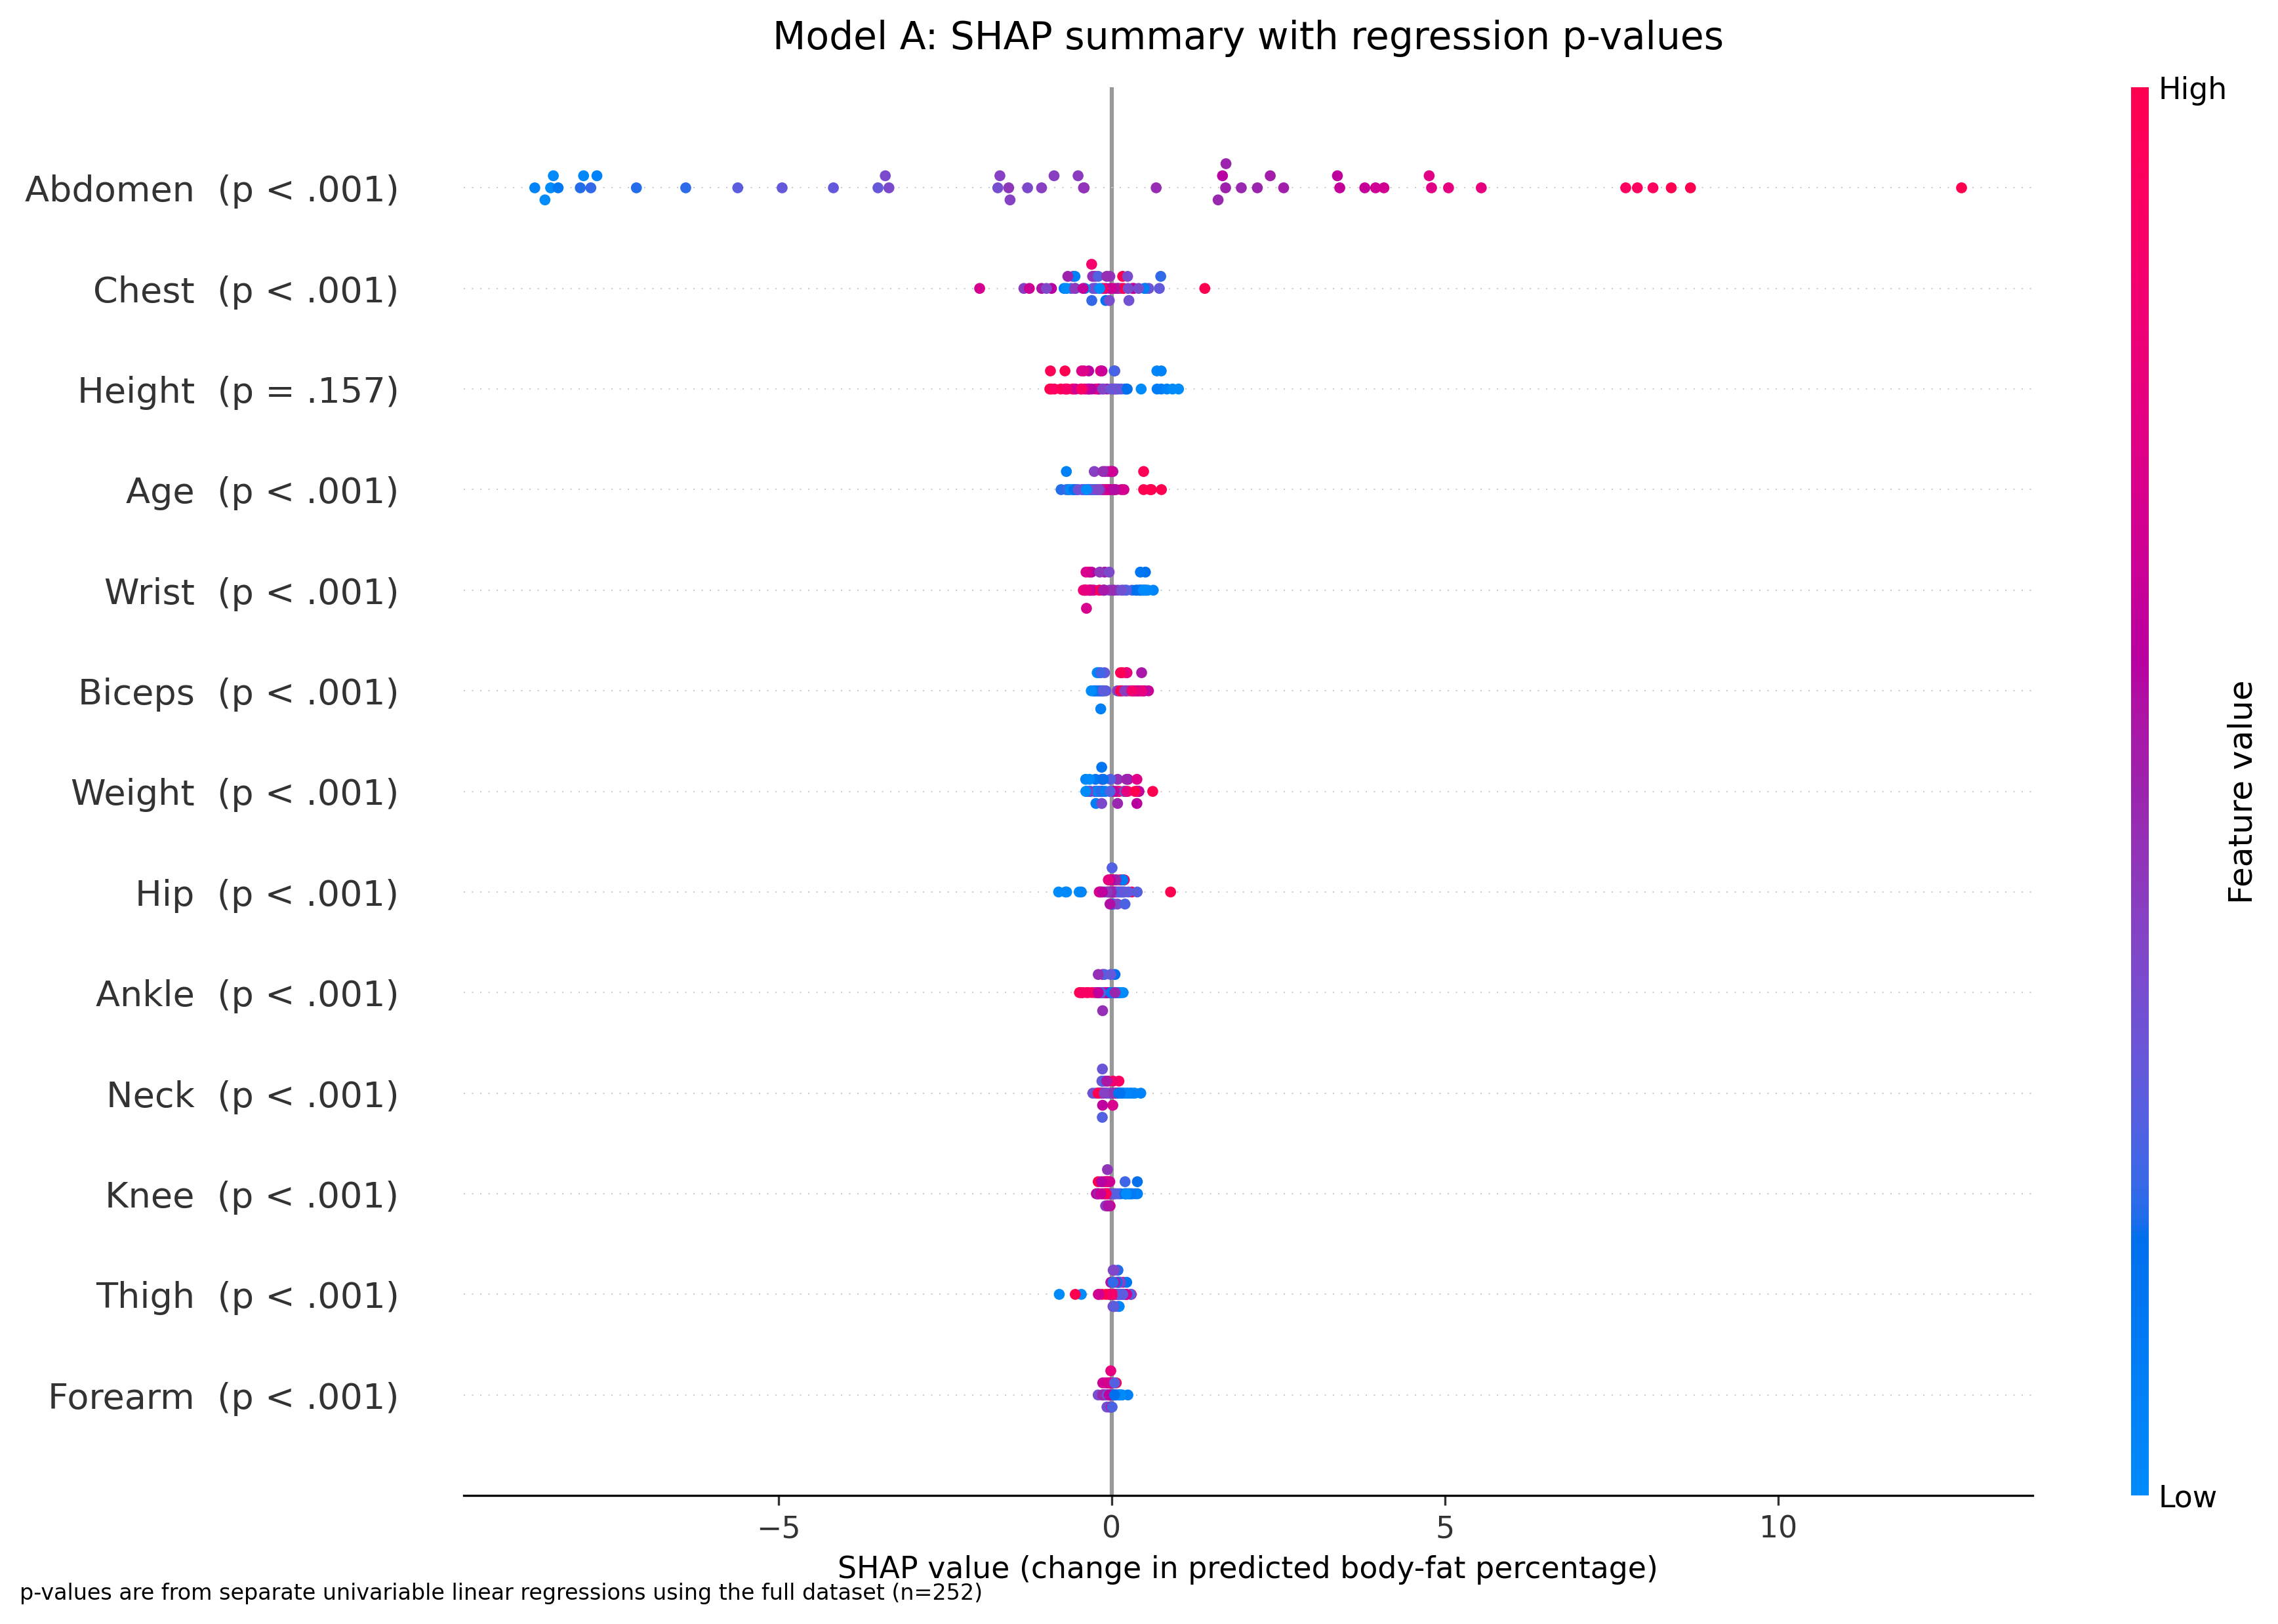

Saved: c:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\bodyfat\statistical_summary\model_b_xgboost_shap_with_pvalues.png


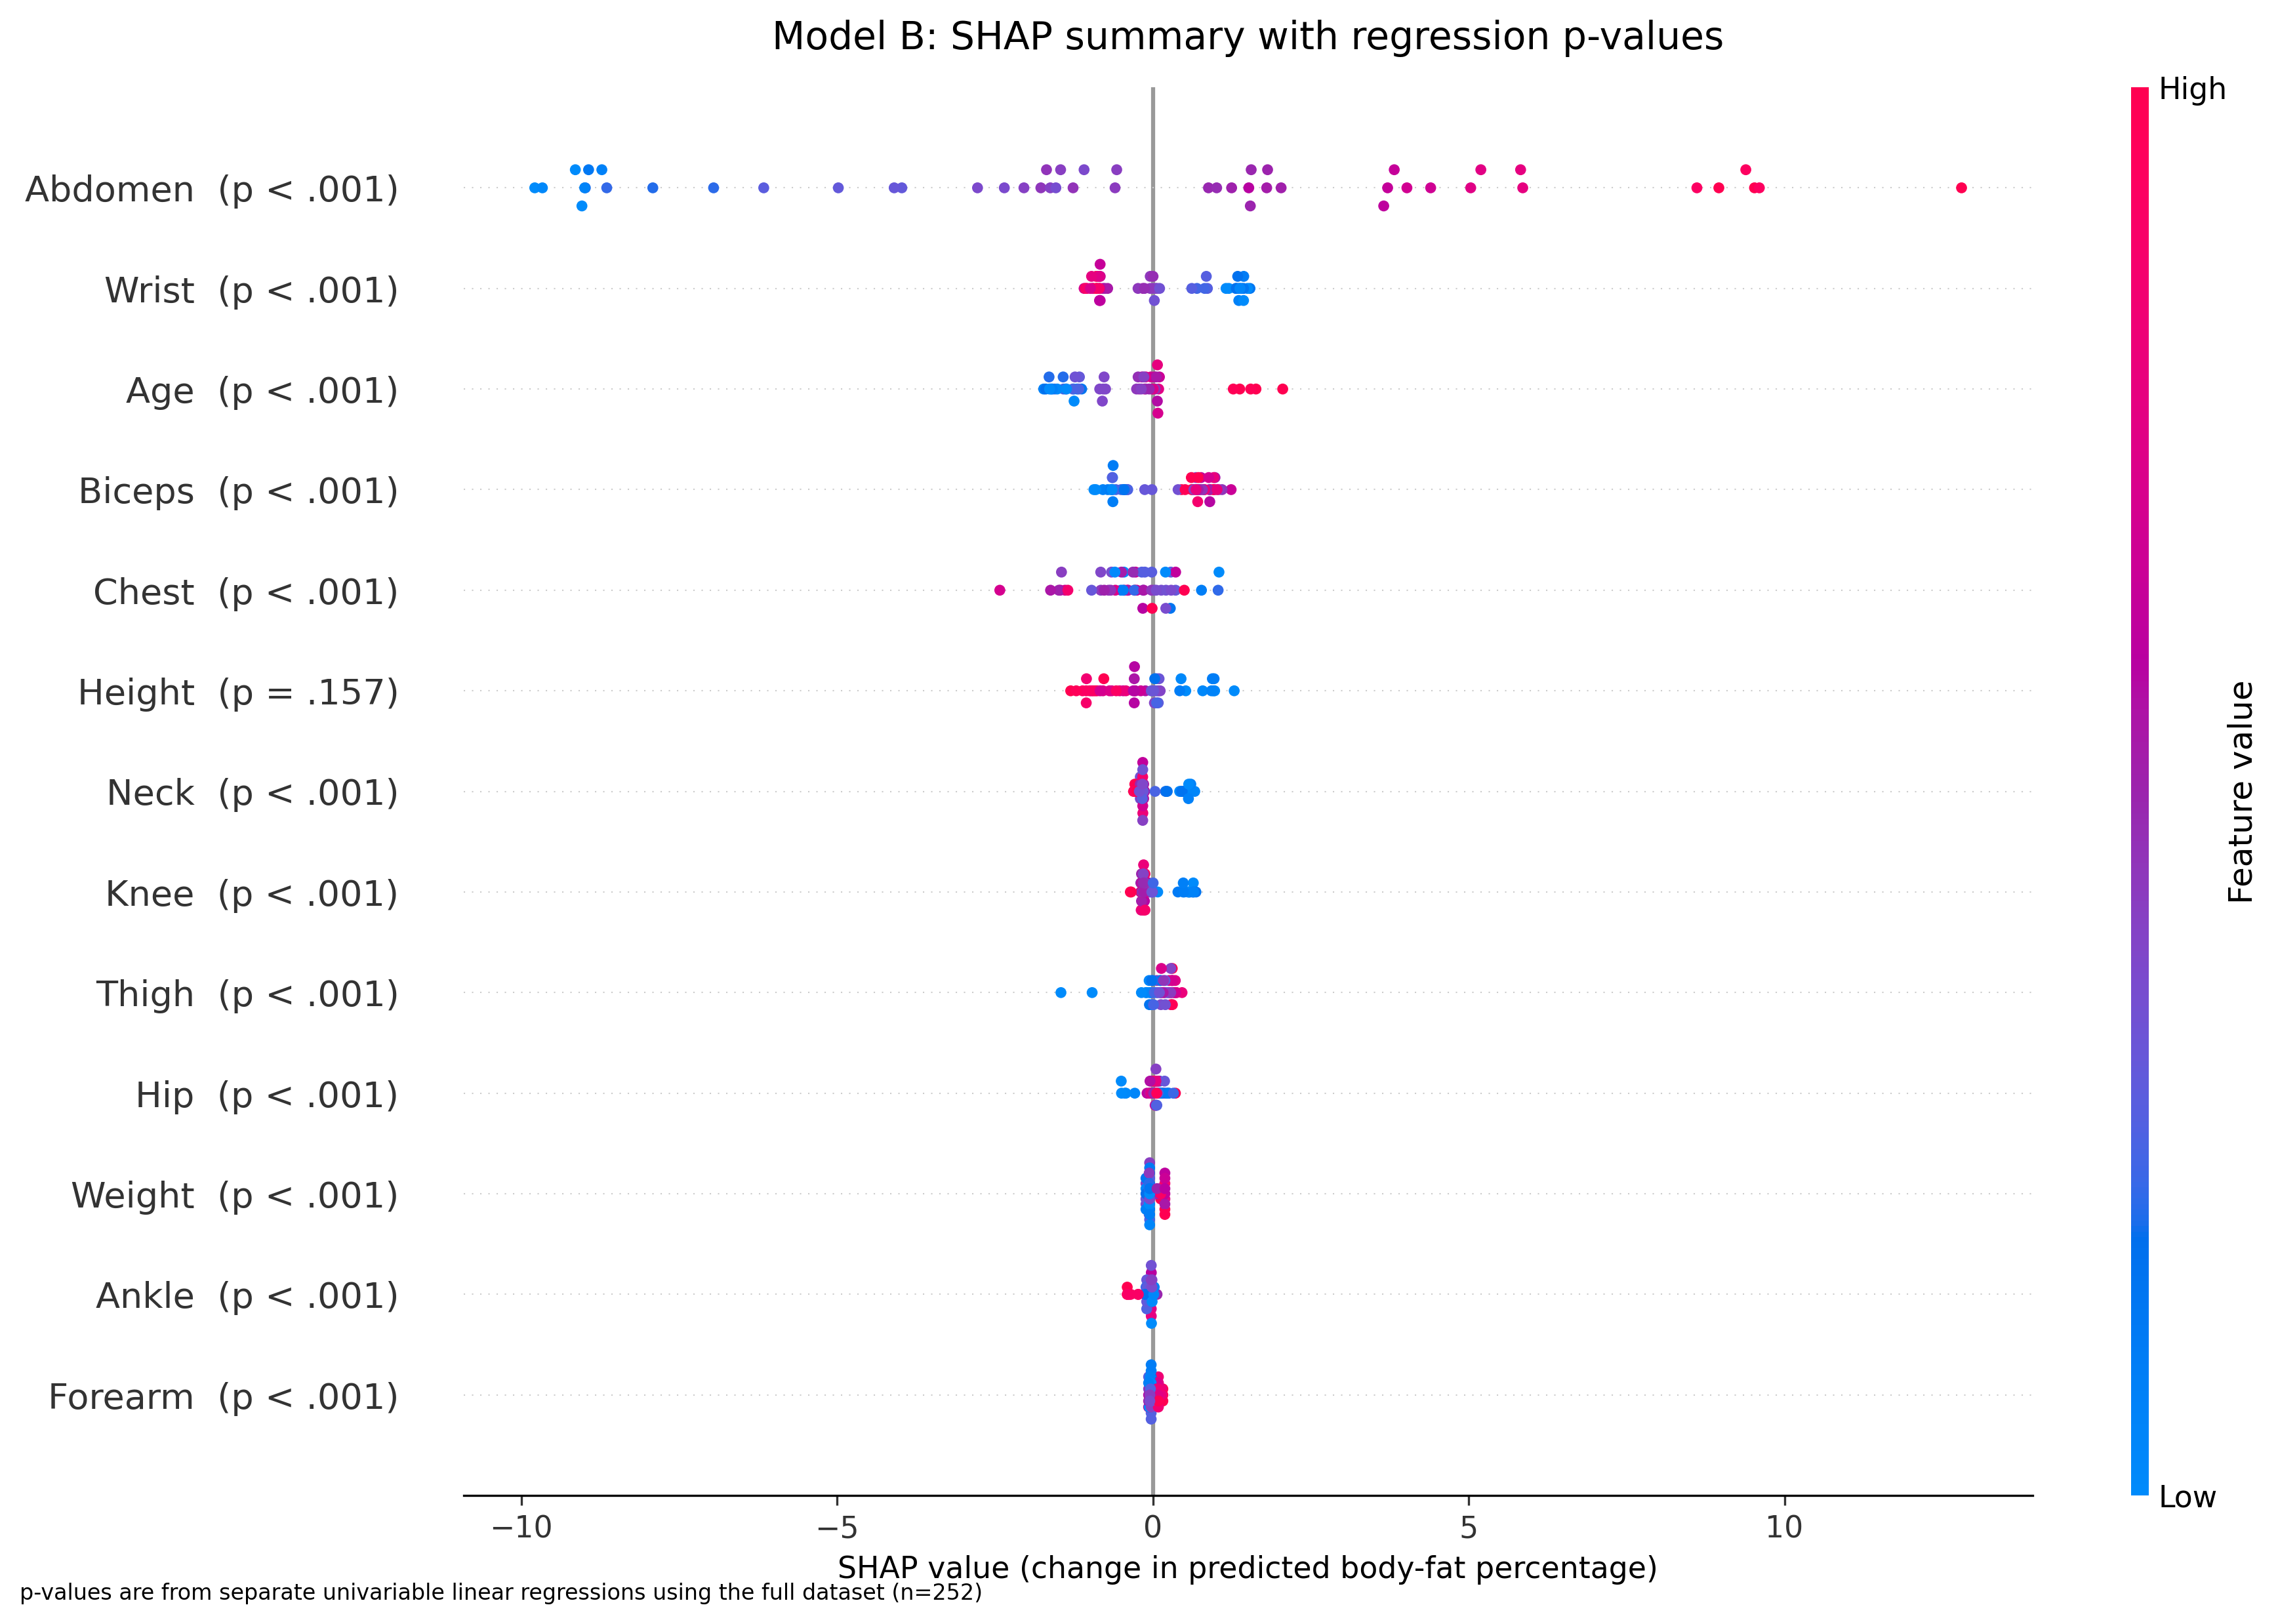

In [6]:
def format_p_value(p_value):
    if p_value < 0.001:
        return 'p < .001'
    return f'p = {p_value:.3f}'.replace('0.', '.')


p_value_lookup = regression_results.set_index('Feature')['p-value'].to_dict()
feature_labels = {
    feature: f'{feature}  ({format_p_value(p_value_lookup[feature])})'
    for feature in FEATURES
}
generated_plots = {}

for archive_key, (anonymous_name, filename) in MODEL_PLOTS.items():
    display_features = X_test[FEATURES].copy()
    display_features.columns = [feature_labels[feature] for feature in FEATURES]

    shap.summary_plot(
        shap_archive[archive_key],
        display_features,
        max_display=len(FEATURES),
        plot_size=(12.5, 8.0),
        show=False,
    )
    figure = plt.gcf()
    axis = plt.gca()
    axis.set_title(
        f'{anonymous_name}: SHAP summary with regression p-values',
        fontsize=14,
        pad=14,
    )
    axis.set_xlabel(
        'SHAP value (change in predicted body-fat percentage)',
        fontsize=11,
    )
    figure.text(
        0.01,
        0.01,
        (
            'p-values are from separate univariable linear regressions '
            'using the full dataset (n=252)'
        ),
        ha='left',
        va='bottom',
        fontsize=8,
    )
    output_path = OUTPUT_DIR / filename
    figure.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    generated_plots[anonymous_name] = output_path
    plt.close(figure)

    print(f'Saved: {output_path}')
    display(Image(filename=str(output_path)))

## Interpretation cautions

- A small regression p-value indicates evidence of a marginal linear association with observed body-fat percentage; it does not measure the size or practical importance of that association. Use the coefficient and confidence interval for those purposes.
- A large SHAP magnitude indicates that a fitted model relies strongly on a feature for its predictions. It does not imply that the feature has a causal effect on body fat.
- Regression and SHAP results can differ legitimately because the univariable regression treats one measurement at a time, whereas the machine-learning models can use correlated measurements, nonlinear relationships and interactions simultaneously.
- The displayed p-values should therefore be described as an independent statistical reference, not as a validation or significance test of SHAP.